<a href="https://colab.research.google.com/github/AnandJL/Exit-Test-ICT/blob/main/Exit_test_Anand_JL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 Task 1: Data Understanding & Exploration

In [334]:
import pandas as pd

In [335]:
df = pd.read_csv('/content/drive/MyDrive/DSA/Exit/G2.csv')

In [336]:
df.head()

,id,name,height_dm,weight_hg,base_experience,type_1,type_2,hp,attack,defense
0,1,bulbasaur,7,69,64.0,grass,poison,45,49,49
1,2,ivysaur,10,130,142.0,grass,poison,60,62,63
2,3,venusaur,20,1000,236.0,grass,poison,80,82,83
3,4,charmander,6,85,62.0,fire,NaN,39,52,43
4,5,charmeleon,11,190,142.0,fire,NaN,58,64,58


In [337]:
df.dtypes

,0
id,int64
name,object
height_dm,int64
weight_hg,int64
base_experience,float64
type_1,object
type_2,object
hp,int64
attack,int64
defense,int64


**Numerical features** - id, height_dm, weight_hg, base_experience, hp, attack, defense.

**Categorical features** - name, type_1, type_2.

In [338]:
df.describe()

,id,height_dm,weight_hg,base_experience,hp,attack,defense
count,1351.000000,1351.000000,1351.000000,1302.000000,1351.000000,1351.000000,1351.000000
mean,2841.692080,20.443375,991.059956,161.943932,71.673575,82.757957,76.193930
std,4139.019112,53.238467,1953.115812,82.532554,26.827529,32.351906,30.712902
min,1.000000,1.000000,0.000000,36.000000,1.000000,5.000000,5.000000
25%,338.500000,6.000000,94.500000,71.000000,55.000000,60.000000,55.000000
50%,676.000000,11.000000,326.000000,165.000000,70.000000,80.000000,70.000000
75%,1013.500000,17.000000,853.500000,222.500000,85.000000,102.500000,95.000000
max,10326.000000,1000.000000,10000.000000,608.000000,255.000000,190.000000,250.000000


In [339]:
df.isna().sum()

,0
id,0
name,0
height_dm,0
weight_hg,0
base_experience,49
type_1,0
type_2,586
hp,0
attack,0
defense,0


In [340]:
df.duplicated().sum()

np.int64(0)

In [341]:
df['type_1'].value_counts()

,count
type_1,
water,160
normal,139
grass,122
electric,100
bug,95
psychic,86
fire,84
rock,83
dark,63


In [342]:
df['type_2'].value_counts()

,count
type_2,
flying,141
dragon,58
psychic,56
poison,54
fairy,53
steel,47
fighting,47
ground,46
ghost,44


In [343]:
df['type_2'].value_counts().sum()

np.int64(765)

In [344]:
import seaborn as sns
import matplotlib.pyplot as plt

<Axes: title={'center': 'Histogram of type_1'}, xlabel='type_1', ylabel='Count'>

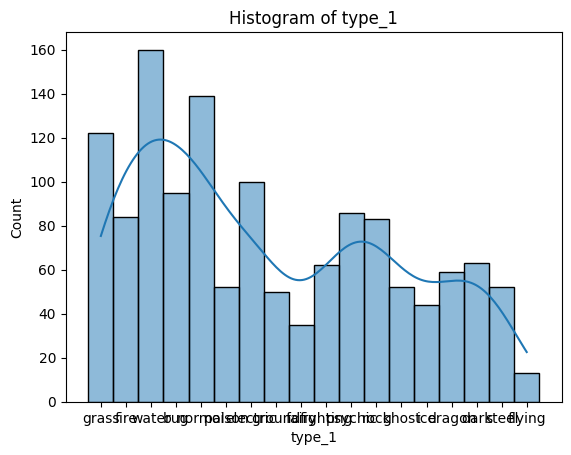

In [345]:
plt.title('Histogram of type_1')
sns.histplot(data=df, x='type_1', kde=True)

<Axes: title={'center': 'Histogram of type_2'}, xlabel='type_2', ylabel='Count'>

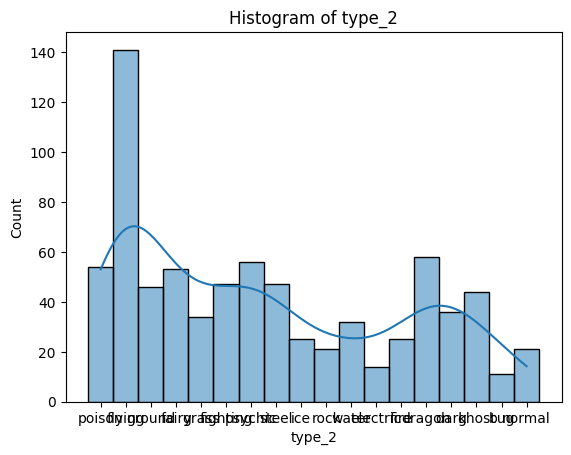

In [346]:
plt.title('Histogram of type_2')
sns.histplot(data=df, x='type_2', kde=True)

<Axes: ylabel='type_1'>

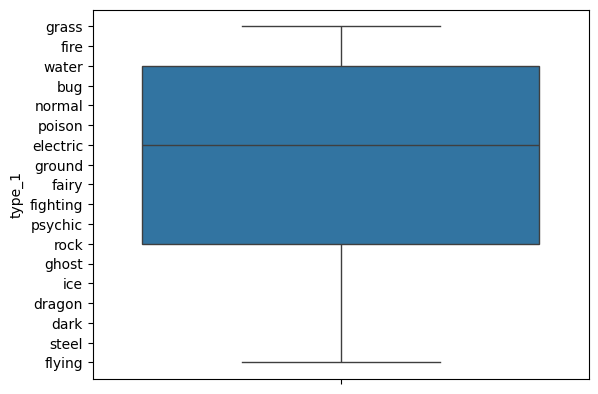

In [347]:
sns.boxplot(data=df, y='type_1')

<Axes: ylabel='type_2'>

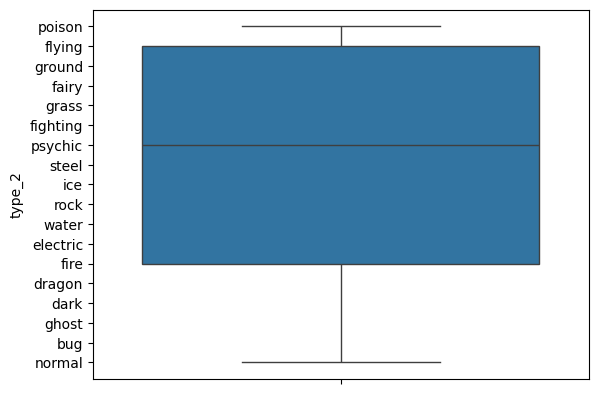

In [348]:
sns.boxplot(data=df, y='type_2')

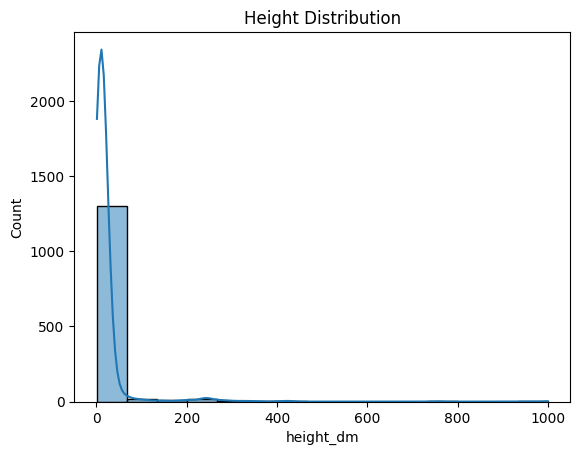

In [349]:
sns.histplot(df['height_dm'], kde=True,bins=15)
plt.title('Height Distribution')
plt.show()

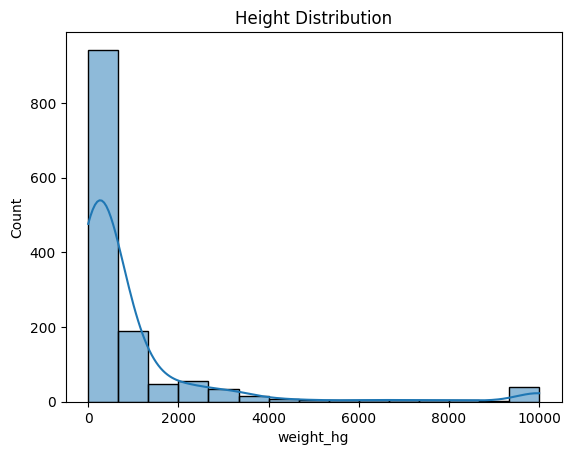

In [350]:
sns.histplot(df['weight_hg'], kde=True, bins=15)
plt.title('Height Distribution')
plt.show()

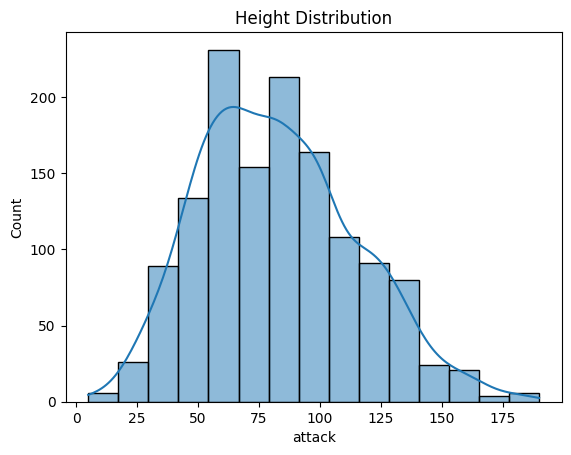

In [351]:
sns.histplot(df['attack'], kde=True, bins=15)
plt.title('Height Distribution')
plt.show()

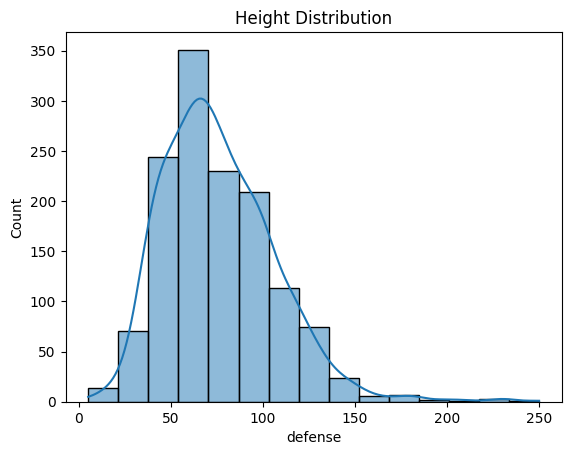

In [352]:
sns.histplot(df['defense'], kde=True, bins=15)
plt.title('Height Distribution')
plt.show()

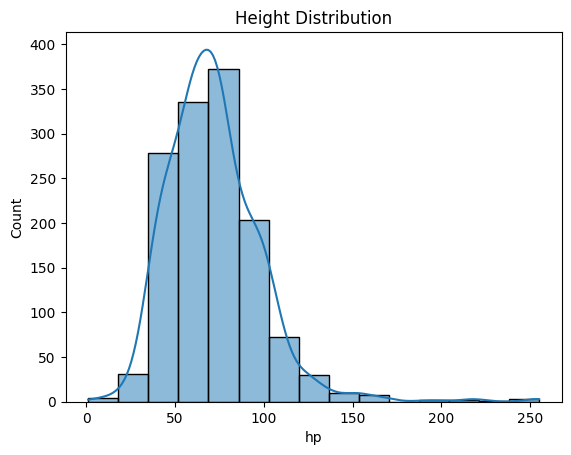

In [353]:
sns.histplot(df['hp'], kde=True, bins=15)
plt.title('Height Distribution')
plt.show()

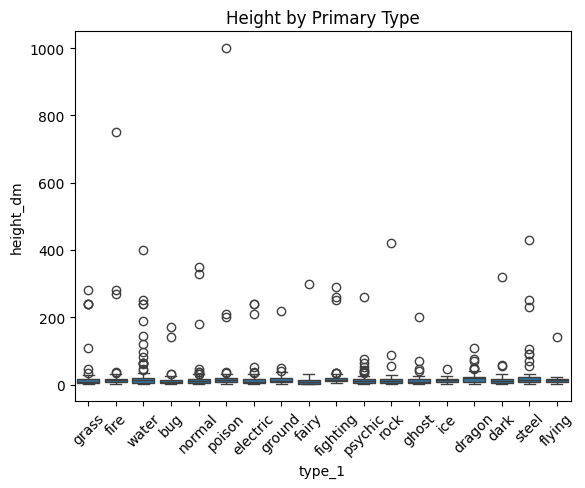

In [354]:
sns.boxplot(data=df, x='type_1', y='height_dm')
plt.xticks(rotation=45)
plt.title('Height by Primary Type')
plt.show()

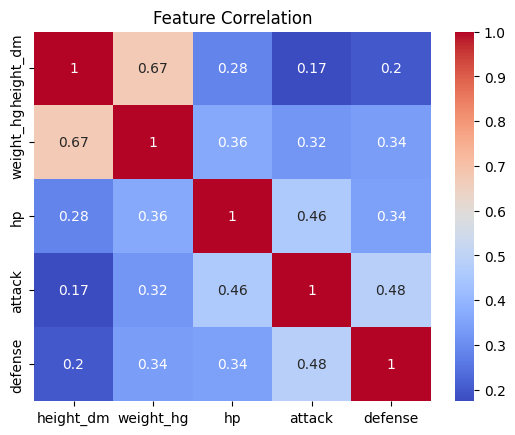

In [355]:
numeric_features = [
    'height_dm',
    'weight_hg',
    'hp',
    'attack',
    'defense'
]

sns.heatmap(
    df[numeric_features].corr(),
    annot=True,
    cmap='coolwarm'
)
plt.title('Feature Correlation')
plt.show()

In [356]:
df[numeric_features].std().sort_values(ascending=False)

,0
weight_hg,1953.115812
height_dm,53.238467
attack,32.351906
defense,30.712902
hp,26.827529


Analytical Questions -

1. Water appears most frequently in the dataset.
2. weight_hg shows the greatest variation.
3. The dataset is suitable for predicting type_1, but it has missing values, outliers, and an imbalanced target class that should be addressed.

Task 2- Data Preprocessing

In [357]:
df['base_experience'] = df['base_experience'].fillna(df['base_experience'].median())

In [358]:
#Fill type 2 null values as NAN
df['type_2'] = df['type_2'].fillna('NAN')

In [359]:
df['name'].value_counts()

,count
name,
bulbasaur,1
ivysaur,1
venusaur,1
charmander,1
charmeleon,1
...,...
tatsugiri-curly-mega,1
tatsugiri-droopy-mega,1
tatsugiri-stretchy-mega,1


In [360]:
from sklearn.preprocessing import LabelEncoder

df['type_1'] = LabelEncoder().fit_transform(df['type_1'])

In [361]:
#drop type_2
df.drop('type_2', axis=1, inplace=True)

In [362]:
df.head()

,id,name,height_dm,weight_hg,base_experience,type_1,hp,attack,defense
0,1,bulbasaur,7,69,64.0,9,45,49,49
1,2,ivysaur,10,130,142.0,9,60,62,63
2,3,venusaur,20,1000,236.0,9,80,82,83
3,4,charmander,6,85,62.0,6,39,52,43
4,5,charmeleon,11,190,142.0,6,58,64,58


In [363]:
from sklearn.model_selection import train_test_split


X = df[numeric_features]
y = df['type_1']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

pd.Series(y_train).value_counts()

(1080, 5) (271, 5)
(1080,) (271,)


,count
type_1,
17,128
12,111
9,97
3,80
0,76
14,69
6,67
15,66
1,50


In [364]:
#Scaling
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train[numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_test[numeric_features] = scaler.transform(X_test[numeric_features])

Analytical Questions -

1. Preprocessing makes data consistent and usable by the model, handles missing or duplicate values, and helps prevent unreliable results or data leakage.

2. The missing values in type_2 need not be handled. I dropped the type_2 feature because it is not either physical or combat features that we can use for model creation.

Task 3 - EDA

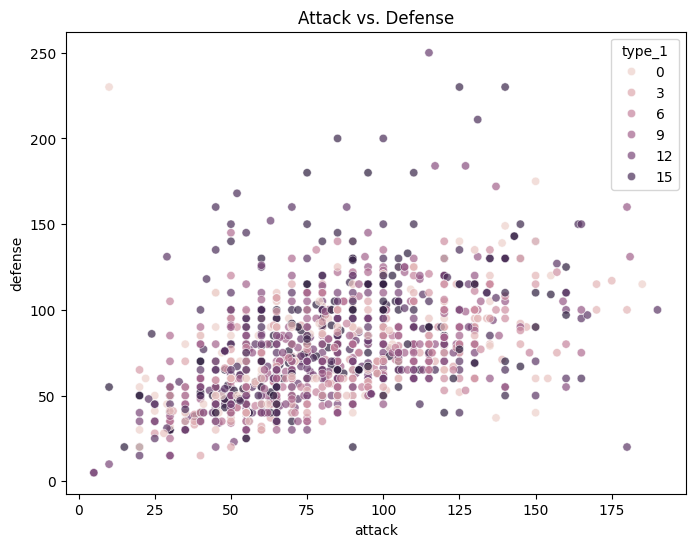

In [365]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='attack', y='defense', hue='type_1', alpha=0.7)
plt.title('Attack vs. Defense')
plt.show()

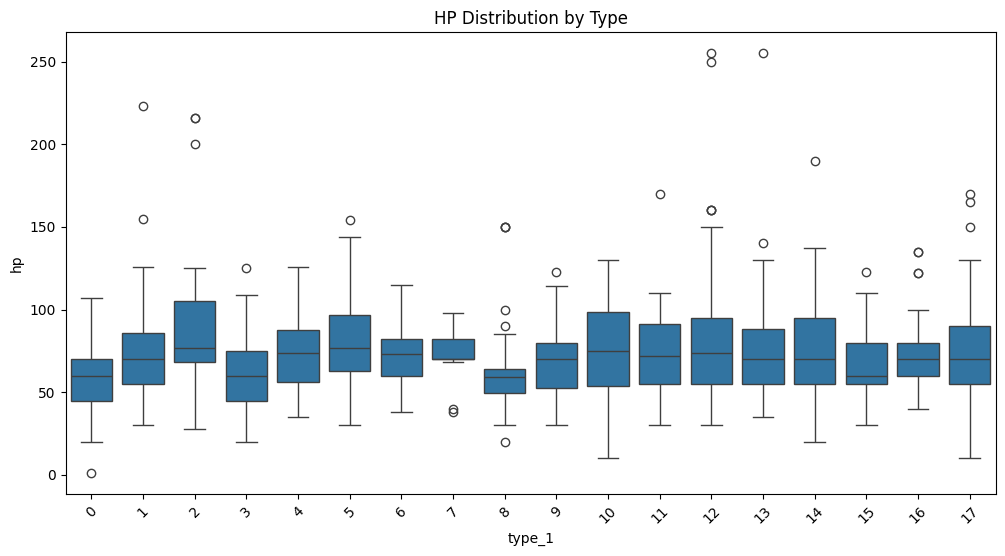

In [366]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='type_1', y='hp')
plt.xticks(rotation=45)
plt.title('HP Distribution by Type')
plt.show()

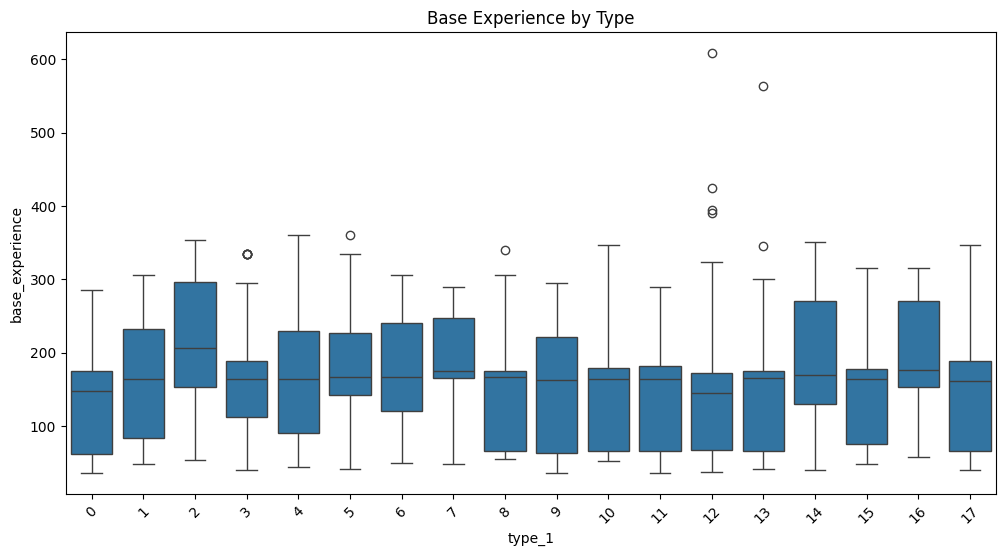

In [367]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='type_1', y='base_experience')
plt.xticks(rotation=45)
plt.title('Base Experience by Type')
plt.show()

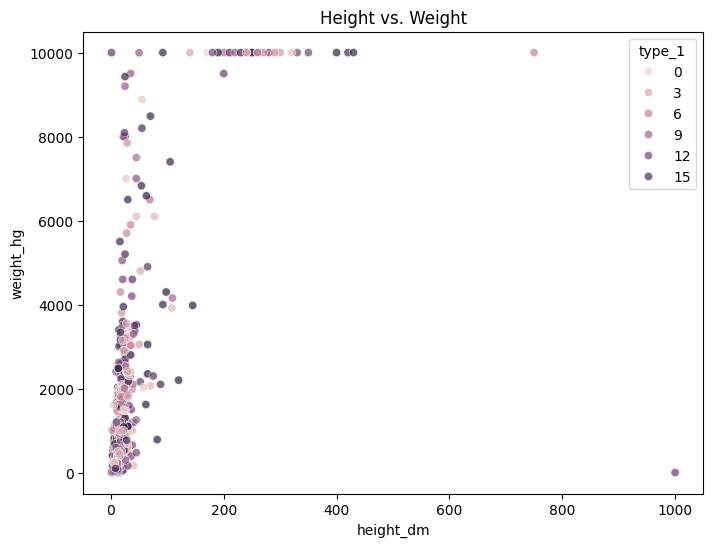

In [368]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='height_dm', y='weight_hg', hue='type_1', alpha=0.7)
plt.title('Height vs. Weight')
plt.show()

In [369]:
df.groupby('type_1')['attack'].mean()

,attack
type_1,
0,72.631579
1,88.952381
2,103.237288
3,74.090000
4,71.228571
5,110.435484
6,86.190476
7,82.769231
8,72.961538


Analytical Questions -

1. Fighting/ground/dragon types appear strongest; confirm the exact ranking with df.groupby('type_1')['attack'].mean()

2. There is a positive relationship—heavier Pokémon generally tend to be taller, though the scatter shows considerable spread.

3.  attack, defense, and weight_hg appear to best distinguish types; height_dm and HP show more overlap.



TASK 4 - ML Model

In [370]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

In [371]:
#Logistic Regression
log_model = LogisticRegression()
log_model.fit(X_train,y_train)
y_pred = log_model.predict(X_test)

In [372]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

print(confusion_matrix(y_test,y_pred))
print(accuracy_score(y_test,y_pred))

[[ 1  0  0  3  0  2  0  0  0  1  0  0  1  0  0  2  2  7]
 [ 1  0  1  1  0  1  0  0  0  1  0  0  2  0  0  1  0  5]
 [ 1  0  2  1  0  1  0  0  0  0  0  0  2  0  0  1  0  4]
 [ 0  0  0  7  0  1  1  0  0  2  0  0  3  0  0  2  0  4]
 [ 0  0  0  1  0  0  0  0  0  0  0  0  3  0  0  0  0  3]
 [ 0  0  1  1  0  1  0  0  0  2  0  0  2  0  0  3  0  2]
 [ 0  0  0  1  0  1  0  0  0  1  0  0  5  0  0  2  0  7]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  2  0  0  0  0  1]
 [ 2  0  0  1  0  0  0  0  0  2  0  0  1  0  0  1  0  3]
 [ 3  0  0  2  0  0  1  0  0  2  0  0  4  0  0  2  0 11]
 [ 3  0  1  1  0  0  0  0  0  0  0  0  1  0  0  2  0  2]
 [ 0  0  0  2  0  1  0  0  0  0  0  0  2  0  0  0  0  4]
 [ 0  0  1  4  0  1  0  0  0  2  0  0 10  0  0  0  0 10]
 [ 1  0  0  0  0  0  0  0  0  0  0  0  2  0  0  2  0  5]
 [ 1  0  1  0  0  2  0  0  0  1  1  0  1  0  0  1  0  9]
 [ 2  0  0  1  0  2  0  0  0  2  0  0  2  0  0  3  1  4]
 [ 0  0  0  0  0  0  0  0  0  0  2  0  0  0  0  3  2  3]
 [ 4  0  1  1  0  1  0  0  0  0

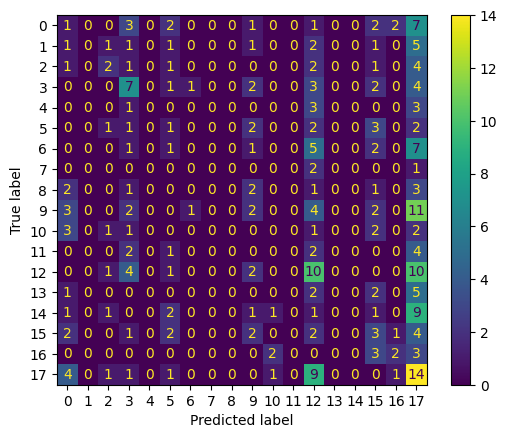

In [373]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=log_model.classes_)
plt.show()

In [376]:
#KNN
import numpy as np

metric_k=[]
neighbours = np.arange(3,20)

for i in neighbours:
    knn_model = KNeighborsClassifier(n_neighbors=i)
    knn_model.fit(X_train,y_train)
    y_pred_knn = knn_model.predict(X_test)
    metric_k.append(accuracy_score(y_test,y_pred_knn))

    metric_k

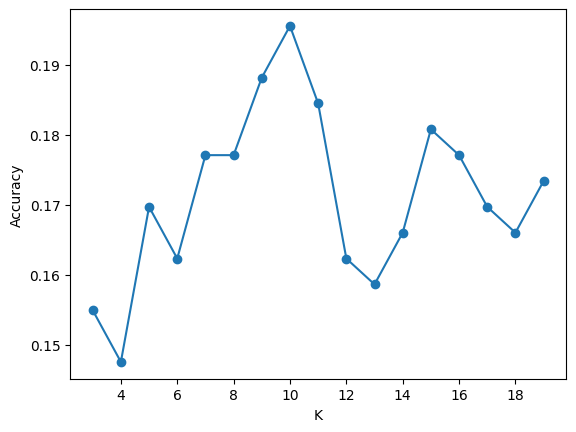

In [377]:
plt.plot(neighbours,metric_k,marker='o')
plt.xlabel('K')
plt.ylabel('Accuracy')
plt.show()

In [378]:
knn_classifier = KNeighborsClassifier(n_neighbors=11)
knn_classifier.fit(X_train,y_train)
y_pred_knn = knn_classifier.predict(X_test)
print(accuracy_score(y_test,y_pred_knn))
print(confusion_matrix(y_test,y_pred_knn))

0.18450184501845018
[[4 2 1 2 0 1 2 0 0 1 0 0 1 0 1 2 0 2]
 [1 1 1 1 0 1 1 1 0 2 0 0 1 0 0 0 0 3]
 [5 0 4 2 0 0 0 0 0 0 0 0 0 0 0 1 0 0]
 [2 0 1 8 0 1 3 0 1 1 0 0 2 0 0 1 0 0]
 [2 0 0 1 0 0 1 0 0 1 0 0 0 0 0 0 0 2]
 [4 0 2 1 0 0 0 0 0 2 0 0 1 0 0 1 0 1]
 [2 2 0 3 0 1 5 1 0 1 0 0 0 0 1 0 1 0]
 [0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 1 0 0]
 [2 1 0 2 0 0 1 0 1 1 0 0 0 0 0 0 1 1]
 [6 2 1 2 0 2 1 0 1 5 0 0 1 0 2 1 0 1]
 [2 1 1 0 0 2 1 0 0 2 0 0 0 0 0 1 0 0]
 [3 1 1 1 0 0 1 0 0 0 0 0 1 0 0 0 0 1]
 [3 2 1 3 0 2 6 0 0 1 0 0 9 0 1 0 0 0]
 [2 1 0 0 0 1 0 0 0 2 0 0 1 0 0 0 1 2]
 [0 1 1 2 0 1 3 0 0 1 2 0 1 0 2 0 1 2]
 [0 2 0 1 0 0 2 0 1 1 0 0 0 0 0 4 2 4]
 [1 0 0 0 0 0 0 0 1 0 1 0 1 0 0 2 2 2]
 [4 0 3 3 0 1 3 0 1 3 0 0 7 0 1 0 1 5]]


In [379]:
#Random Forest

rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train,y_train)
y_pred_rf = rf_model.predict(X_test)

print(accuracy_score(y_test,y_pred_rf))
print(confusion_matrix(y_test,y_pred_rf))

0.24723247232472326
[[6 0 1 0 1 1 2 0 0 2 0 0 0 0 0 2 0 4]
 [1 2 0 2 1 0 0 0 0 1 0 1 2 0 0 0 0 3]
 [0 0 3 0 1 0 2 0 0 0 0 0 1 0 0 2 0 3]
 [0 0 1 7 0 0 1 0 0 4 0 0 3 0 0 0 1 3]
 [0 0 0 1 1 0 2 0 0 1 0 0 1 0 0 1 0 0]
 [3 0 2 0 0 1 0 0 0 1 0 0 2 0 0 0 0 3]
 [1 0 1 1 0 1 5 0 0 1 0 1 3 0 1 0 1 1]
 [0 0 0 1 0 0 1 0 0 1 0 0 0 0 0 0 0 0]
 [1 0 0 0 0 1 0 0 2 1 0 1 0 1 1 1 1 0]
 [2 0 1 0 0 0 0 0 2 8 0 0 1 2 3 1 0 5]
 [1 0 1 1 0 1 1 0 0 0 2 0 0 0 0 1 0 2]
 [2 1 0 0 0 1 2 0 0 0 0 0 2 0 0 0 0 1]
 [1 5 1 1 0 1 3 0 1 2 0 0 9 0 1 0 0 3]
 [1 0 1 0 0 0 0 0 1 1 1 1 1 0 0 0 0 3]
 [1 0 1 2 0 1 0 0 1 0 2 0 1 0 6 0 0 2]
 [3 0 0 1 0 1 0 0 1 0 0 0 0 0 2 6 0 3]
 [0 0 0 0 0 0 0 1 0 0 1 0 0 0 1 2 2 3]
 [2 1 4 2 0 0 2 0 1 2 0 0 7 1 2 1 0 7]]


In [380]:
rf_model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}

In [383]:
rf_model = RandomForestClassifier(random_state=42,n_estimators=200,n_jobs=-1,class_weight='balanced',max_depth=10,min_samples_split=5)

rf_model.fit(X_train,y_train)
y_pred_rf = rf_model.predict(X_test)

print(accuracy_score(y_test,y_pred_rf))
print(confusion_matrix(y_test,y_pred_rf))

0.24354243542435425
[[7 0 1 0 2 3 1 0 1 1 0 0 0 0 0 1 1 1]
 [1 3 0 0 2 1 2 0 0 1 0 2 1 0 0 0 0 0]
 [0 0 4 0 0 0 2 0 0 0 0 0 1 0 0 1 1 3]
 [0 0 1 7 0 0 6 0 0 2 0 1 1 0 0 0 1 1]
 [0 0 0 0 1 0 1 0 1 0 0 0 2 0 0 0 1 1]
 [2 0 2 2 0 1 0 0 0 2 0 0 0 1 0 0 1 1]
 [1 0 1 1 0 0 5 1 1 1 0 2 1 0 2 0 1 0]
 [0 0 1 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0]
 [1 0 0 0 0 0 0 0 2 1 0 2 0 1 1 1 1 0]
 [1 0 1 1 1 1 3 0 1 4 0 0 2 2 3 2 0 3]
 [0 1 1 0 0 1 2 0 0 0 2 1 0 0 0 1 1 0]
 [1 0 0 0 0 1 3 0 0 0 0 2 1 0 1 0 0 0]
 [2 3 1 1 1 1 3 0 1 3 1 1 9 0 0 0 0 1]
 [0 0 1 1 0 1 0 0 1 0 0 1 1 1 0 0 1 2]
 [1 0 1 0 1 2 1 0 1 0 2 2 0 0 5 0 0 1]
 [3 0 0 0 0 1 1 1 1 0 0 2 0 0 0 5 0 3]
 [0 0 0 0 0 0 0 1 0 0 1 0 0 1 2 1 4 0]
 [1 1 3 0 0 1 2 1 1 5 0 0 3 3 3 1 3 4]]


In [385]:
# Decision Tree

from sklearn.tree import DecisionTreeClassifier
dec_tree=DecisionTreeClassifier(random_state=30)
dec_tree.fit(X_train, y_train)
y_pred_dt=dec_tree.predict(X_test)

In [390]:


from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

feature_names = [str(name) for name in X_train.columns]
class_names = [str(name) for name in label_encoder.classes_]

plt.figure(figsize=(15,10))
plot_tree(dec_tree, feature_names=feature_names, class_names=class_names, filled=True, rounded=True);
plt.show()

AttributeError: 'LabelEncoder' object has no attribute 'classes_'